# Praktikum Sub-CPMK-3 &mdash; Transformasi dan Penapisan pada Domain Frekuensi

**Pengolahan Citra Digital (IF2514505)** &nbsp;|&nbsp; Semester 5 &nbsp;|&nbsp; 1 SKS Praktikum &nbsp;|&nbsp; Durasi sasaran 135 menit (rentang 120&ndash;150)

**Program Studi Informatika &mdash; Institut Teknologi Kalimantan**

---

| | |
|---|---|
| **Nama** | Muhammad Wisnu Wardhana |
| **NIM** | 11241063 |
| **Kelas / Kelompok** | A |
| **Tanggal praktikum** | 11/11/2026 |

---

> **Catatan sebelum dikumpulkan:** ganti bagian identitas yang masih bertanda `[Isi ...]` dengan data Anda sendiri. Isi kode, keluaran, dan analisis mengikuti contoh Lisa serta tahapan pada modul.

### Capaian yang diukur
**Sub-CPMK-3**: Mahasiswa mampu menerapkan transformasi citra pada domain frekuensi dan penapisan berbasis frekuensi.

### Rujukan utama
Gonzalez, R.C. dan Woods, R.E. (2018) *Digital Image Processing*, edisi ke-4, Bab 4 (§4.4&ndash;4.10). Nomor persamaan mengikuti buku tersebut.

### Petunjuk pengerjaan
1. Jalankan sel berurutan. Sel bertanda `# TODO` wajib Anda lengkapi sendiri.
2. Setiap blok **Analisis** diisi kalimat Anda sendiri dan **wajib memuat angka** dari keluaran Anda.
3. Citra uji dibangkitkan di dalam notebook (benih tetap) &mdash; **tidak perlu mengunggah berkas**.
4. Bagian bertanda **[Pengayaan]** boleh dilewati; jalur inti selesai dalam &plusmn;120 menit.
5. Konvensi indeks: pada `np.fft.fft2(f)[u, v]`, **u mengikuti baris dan v mengikuti kolom**, sama dengan Gonzalez (x = arah baris).
6. Kumpulkan dalam keadaan **sudah dijalankan penuh** dengan nama `PraktikumPCD_SubCPMK3_NIM_Nama.ipynb`.

| Bagian | Isi | Menit |
|---|---|---|
| 0 | Persiapan dan citra uji | 10 |
| 1 | DFT dari definisi dan validasinya (§4.4&ndash;4.6) | 25 |
| 2 | Spektrum, sifat translasi, dan peran fase (§4.6) | 15 |
| 3 | Penapisan lolos-rendah: delapan langkah, pelapis, riak, derau (§4.7&ndash;4.8) | 35 |
| 4 | Lolos-tinggi, penekanan frekuensi tinggi, kesetaraan spasial&ndash;frekuensi (§4.9) | 25 |
| 5 | Studi kasus: derau periodik pada citra perairan (§4.10) | 15 |
| 6 | Pemeriksaan akhir dan pengumpulan | 10 |


## Bagian 0 &mdash; Persiapan (10 menit)
Jalankan sel berikut **tanpa diubah**.

NumPy 2.4.6 | OpenCV 5.0.0
kisi               (256, 256) min 38 maks 218
kotak              (256, 256) min 0 maks 255
bersih             (256, 256) min 6 maks 252
berderau           (256, 256) min 0 maks 255
perairan           (240, 360) min 103 maks 196
perairan_bergaris  (240, 360) min 84 maks 217


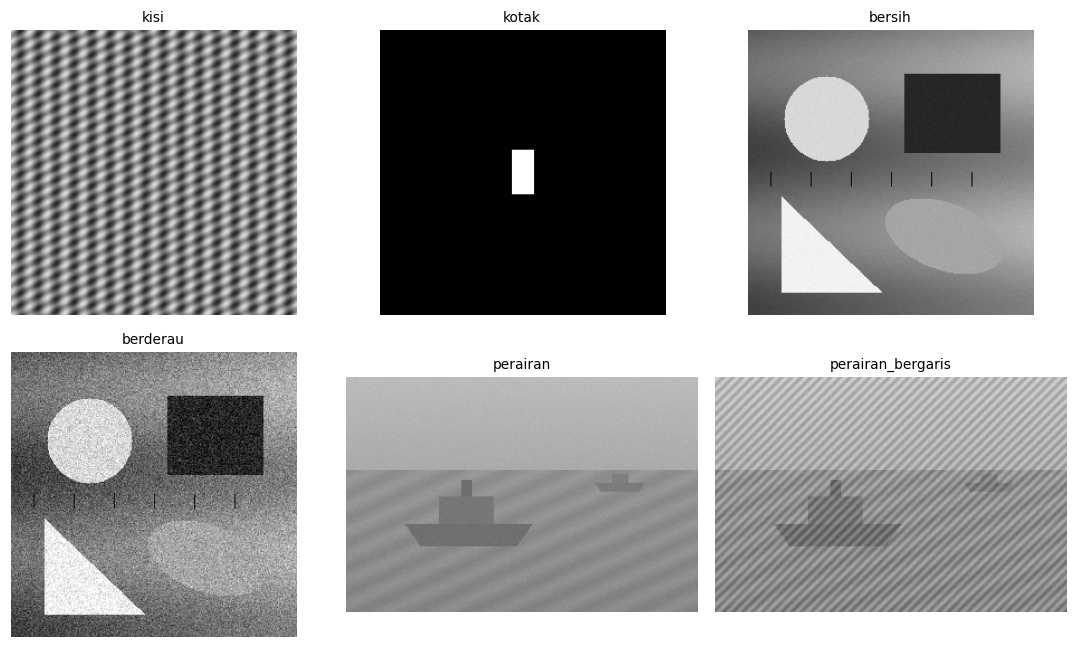

In [1]:
# Sel persiapan — jalankan tanpa diubah
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time

plt.rcParams['figure.dpi'] = 110
print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

"""Pembangkit citra uji sintetis Sub-CPMK-3 (benih acak tetap, hanya NumPy).

Hanya memakai NumPy agar citra identik di versi OpenCV mana pun. Bebas lisensi dan reprodusibel.
"""
import numpy as np

BENIH = 2027


def _grid(h, w):
    return np.mgrid[0:h, 0:w].astype(np.float64)


def _adegan(rng, h=256, w=256):
    """Adegan dasar: gradasi, lingkaran, persegi, elips, segitiga, garis halus (float 0..1)."""
    yy, xx = _grid(h, w)
    img = 0.35 + 0.25 * (xx / w) + 0.10 * np.sin(yy / 23.0)
    img[(xx - 70) ** 2 + (yy - 80) ** 2 <= 38 ** 2] = 0.85
    img[(yy >= 40) & (yy <= 110) & (xx >= 140) & (xx <= 225)] = 0.15
    u, v = xx - 175, yy - 185
    t = np.deg2rad(20)
    ue, ve = u * np.cos(t) + v * np.sin(t), -u * np.sin(t) + v * np.cos(t)
    img[(ue / 55) ** 2 + (ve / 30) ** 2 <= 1] = 0.65
    img[(yy >= 150) & (yy <= 235) & (xx >= 30) & (xx <= 30 + (yy - 150) * 1.05)] = 0.95
    for i in range(6):
        img[128:141, 20 + 36 * i] = 0.05
    img += rng.normal(0, 0.01, img.shape)
    return np.clip(img, 0, 1)


def kisi(h=256, w=256):
    """Dua pola periodik: garis tegak (16 siklus melintang kolom) dan garis miring (u0, v0) = (24, 12)."""
    yy, xx = _grid(h, w)
    g = 128 + 50 * np.cos(2 * np.pi * 16 * xx / w) + 40 * np.cos(2 * np.pi * (24 * yy / h + 12 * xx / w))
    return np.clip(np.floor(g + 0.5), 0, 255).astype(np.uint8)


def kotak(h=256, w=256):
    """Persegi panjang putih di tengah latar hitam (bertepi tajam)."""
    img = np.zeros((h, w), np.uint8)
    img[h // 2 - 20:h // 2 + 20, w // 2 - 10:w // 2 + 10] = 255
    return img


def bersih(rng):
    return np.clip(np.floor(255 * _adegan(rng) + 0.5), 0, 255).astype(np.uint8)


def beri_derau_gauss(img, rng, sigma=20.0):
    return np.clip(np.floor(img.astype(np.float64) + rng.normal(0, sigma, img.shape) + 0.5), 0, 255).astype(np.uint8)


def beri_derau_periodik(img, amp=28.0, u0=12, v0=40):
    """Interferensi sinusoidal: komponen pada (u0, v0) dan (−u0, −v0) dalam indeks DFT (baris, kolom)."""
    h, w = img.shape
    yy, xx = _grid(h, w)
    g = img.astype(np.float64) + amp * np.sin(2 * np.pi * (u0 * yy / h + v0 * xx / w))
    return np.clip(np.floor(g + 0.5), 0, 255).astype(np.uint8)


def perairan(rng, h=240, w=360):
    """Langit, laut, dua kapal, kabut, derau sensor."""
    yy, xx = _grid(h, w)
    cak = 95
    img = np.where(yy < cak, 0.78 - 0.15 * (yy / cak),
                   0.42 + 0.06 * np.sin(xx / 9.0 + yy / 4.0) - 0.10 * ((yy - cak) / (h - cak)))
    img[(yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)] = 0.12
    img[(yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)] = 0.18
    img[(yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)] = 0.10
    img[(yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)] = 0.22
    img[(yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)] = 0.25
    img = 0.45 * img + 0.55 * 0.70
    img += rng.normal(0, 0.010, img.shape)
    return np.clip(np.floor(255 * img + 0.5), 0, 255).astype(np.uint8)


def masker_perairan(h=240, w=360):
    """Masker kebenaran dasar (kapal, laut)."""
    yy, xx = _grid(h, w)
    kapal = np.zeros((h, w), bool)
    kapal |= (yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)
    kapal |= (yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)
    kapal |= (yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)
    kapal |= (yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)
    kapal |= (yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)
    sekitar = np.zeros_like(kapal)
    sekitar[95:185, 45:205] = True
    sekitar[92:125, 245:315] = True
    laut = (yy >= 100) & ~sekitar
    return kapal, laut


def bangkitkan_semua():
    rng = np.random.default_rng(BENIH)
    b = bersih(rng)
    bg = beri_derau_gauss(b, rng)
    air = perairan(rng)
    return {"kisi": kisi(), "kotak": kotak(), "bersih": b, "berderau": bg,
            "perairan": air, "perairan_bergaris": beri_derau_periodik(air, amp=22.0, u0=24, v0=36)}

def tampil(daftar, judul=None, kolom=None, tinggi=3.0, skala=True):
    n = len(daftar); kolom = kolom or n; baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(3.4 * kolom, tinggi * baris)); ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis('off')
    for a, im, t in zip(ax, daftar, judul or [''] * n):
        a.imshow(im, cmap='gray', **({'vmin': 0, 'vmax': 255} if skala else {})); a.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def spektrum_log(f):
    S = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(f.astype(np.float64)))))
    return (255 * S / S.max()).astype(np.uint8)

def psnr(acuan, uji):
    mse = np.mean((acuan.astype(float) - uji.astype(float)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

C = bangkitkan_semua()
kisi_, kotak_, bersih, berderau = C['kisi'], C['kotak'], C['bersih'], C['berderau']
air, air_garis = C['perairan'], C['perairan_bergaris']
kabur = cv2.GaussianBlur(bersih, (9, 9), 1.5)   # masukan Bagian 4
for k, v in C.items(): print(f'{k:18s}', v.shape, 'min', v.min(), 'maks', v.max())
tampil(list(C.values()), list(C.keys()), kolom=3)

## Bagian 1 &mdash; DFT dari definisi (25 menit)

DFT satu variabel (Gonzalez Eq. 4-44) dan inversnya (Eq. 4-45):

$$F(u) = \sum_{x=0}^{M-1} f(x)\,e^{-j2\pi ux/M}, \qquad f(x) = \frac{1}{M}\sum_{u=0}^{M-1} F(u)\,e^{j2\pi ux/M}$$

Dalam bentuk matriks, $F = W f$ dengan $W_{ux} = e^{-j2\pi ux/M}$.

In [2]:
# TODO 1.1 — DFT dan IDFT 1D lewat matriks W. Jangan memakai np.fft di dalam fungsi.
def dft1(f):
    M = len(f); x = np.arange(M)
    W = np.exp(-2j * np.pi * np.outer(x, x) / M )
    return W @ np.asarray(f, dtype=complex)
    ...  # TODO

def idft1(F):
    M = len(F); x = np.arange(M)
    return (np.exp(2j * np.pi * np.outer(x, x) / M) @ F ) / M
    ...  # TODO

# Uji: contoh kuliah f = [3, 1, 2, 2]  ->  F = [8, 1+1j, 2, 1-1j]
# print(np.round(dft1(np.array([3, 1, 2, 2], float)), 6))
# Validasi terhadap np.fft.fft pada vektor acak panjang 64 (selisih maks harus < 1e-9)
print("contoh:", np.round(dft1(np.array([3, 1, 2, 2], float)), 6))
print("invers:", np.round(np.real(idft1(dft1(np.array([3, 1, 2, 2], float)))), 6))
v = np.random.default_rng(0).normal(size=64)
print("selisih maks vs np.fft.fft:", np.abs(dft1(v) - np.fft.fft(v)) .max())





contoh: [8.+0.j 1.+1.j 2.-0.j 1.-1.j]
invers: [3. 1. 2. 2.]
selisih maks vs np.fft.fft: 2.0250662744195385e-13


In [3]:
# TODO 1.2 — DFT 2D dengan sifat keterpisahan (Eq. 4-156): DFT 1D pada setiap kolom, lalu pada setiap baris.
# Bentuk matriks: F = W_M @ f @ W_N. Uji contoh 2×2 [[4, 2], [1, 1]] -> [[8, 2], [4, 2]],
# lalu validasi pada potongan kotak_[96:160, 96:160] terhadap np.fft.fft2.
def dft2(f):
    M, N = f.shape
    WM = np.exp(-2j * np.pi * np.outer(np.arange(M), np.arange(M)) / M)
    WN = np.exp(-2j * np.pi * np.outer(np.arange(N), np.arange(N)) / N)
    return WM @ f.astype(complex) @ WN
    ...  # TODO

print("contoh 2x2:\n", np.round(dft2(np.array([[4, 2], [1, 1]], float)), 6).real)
p = kotak_[96:160, 96:160].astype(float)
print('selisih maks dft2 vs np.fft.fft2 (potongan 64x64):', np.abs(dft2(p) - np.fft.fft2(p)).max())



contoh 2x2:
 [[8. 2.]
 [4. 2.]]
selisih maks dft2 vs np.fft.fft2 (potongan 64x64): 1.2669313427876473e-09


In [4]:
# TODO 1.3 — (a) Buktikan F(0,0) = MN · rerata (Eq. 4-93) pada `bersih`.
# (b) Buktikan pemusatan: DFT dari f(x,y)·(−1)^(x+y) sama dengan np.fft.fftshift(DFT f) (Eq. 4-76).
f = bersih.astype(float)
M, N = f.shape
F = np.fft.fft2(f)
print('(a) F(0,0)        =', F[0, 0])
print('    M·N·rerata    =', M * N * f.mean(), '   (rerata =', round(f.mean(), 4), ')')

x, y = np.indices(f.shape)
F_pusat = np.fft.fft2(f * (-1.0) ** (x + y))
print('(b) selisih maks  |DFT{f(-1)^(x+y)} - fftshift(DFT f)| =', np.abs(F_pusat - np.fft.fftshift(F)).max())

(a) F(0,0)        = (8590323+0j)
    M·N·rerata    = 8590323.0    (rerata = 131.0779 )
(b) selisih maks  |DFT{f(-1)^(x+y)} - fftshift(DFT f)| = 0.0


In [6]:
# [Pengayaan] TODO 1.4 — Bandingkan waktu dft2 (matriks) dan np.fft.fft2 pada citra 256×256. Nisbahnya?
t0 = time.perf_counter(); dft2(bersih.astype(float)); t_m = time.perf_counter() - t0
t0 = time.perf_counter(); np.fft.fft2(bersih.astype(float));  t_f = time.perf_counter() - t0
print(f"matriks {t_m*1e3:.1f} ms | FFT {t_f*1e3:.2f} ms | nisbah {t_m/t_f:.0f}x (bergantung mesin)")



matriks 13.0 ms | FFT 1.25 ms | nisbah 10x (bergantung mesin)


**Analisis 1.** (a) Pada contoh [3, 1, 2, 2], mengapa F(1) dan F(3) saling konjugat? Kaitkan dengan sifat masukan bernilai nyata (Eq. 4-85). (b) Apa arti fisis F(0,0) yang Anda peroleh untuk citra `bersih`? (c) Mengapa spektrum hampir selalu ditampilkan terpusat?

*Jawaban Anda:*
(a). Dari hasil dft1([3, 1, 2, 2]) diperoleh nilai [8, 1+j, 2, 1−j]. Jadi, F(1) = 1+j dan F(3) = 1−j merupakan pasangan konjugat karena keduanya memiliki nilai real yang sama, tetapi bagian imajinernya berbeda tanda. Hal ini sesuai dengan Eq. 4-85, yaitu jika masukan berupa bilangan real, maka hasil transformasi Fourier akan memiliki pasangan konjugat. Selain itu, F(0) dan F(2) bernilai real karena keduanya tidak memiliki pasangan konjugat yang berbeda.

(b). Nilai F(0,0) pada citra bersih adalah 8.590.323. Nilai ini merupakan jumlah dari seluruh intensitas piksel pada citra, atau bisa juga diperoleh dari rata-rata intensitas piksel dikalikan jumlah seluruh piksel. Nilai tersebut disebut komponen DC, yang menunjukkan tingkat kecerahan rata-rata pada citra.

(c). Spektrum biasanya ditampilkan di bagian tengah agar komponen frekuensi rendah, terutama DC, berada di tengah, sedangkan frekuensi tinggi berada di bagian pinggir. Dengan tampilan seperti ini, kita lebih mudah melihat pola dan persebaran frekuensi pada citra. Jika tidak dipusatkan, komponen DC akan berada di pojok kiri atas sehingga lebih sulit untuk dibaca dan dianalisis.


## Bagian 2 &mdash; Spektrum, translasi, dan fase (15 menit)

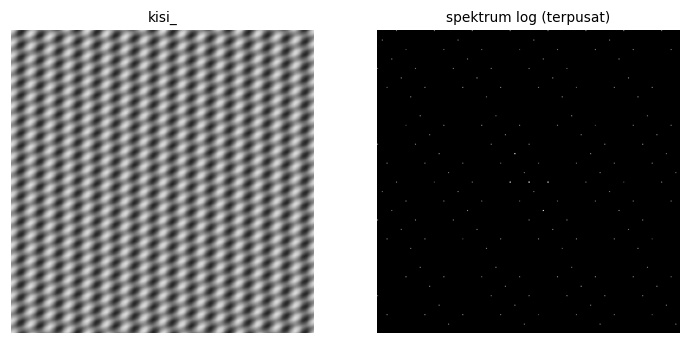

Empat puncak terbesar selain DC:
  (u, v) = (   0,  -16)   |F| = 1637526.2
  (u, v) = (   0,   16)   |F| = 1637526.2
  (u, v) = (  24,   12)   |F| = 1310213.8
  (u, v) = ( -24,  -12)   |F| = 1310213.8


In [5]:
# TODO 2.1 — Tampilkan spektrum log `kisi_`. Cari empat puncak terbesar selain DC dan laporkan koordinatnya
# sebagai (u, v) bertanda (−128..127). Petunjuk: |F| tanpa fftshift, nolkan F[0,0], gunakan np.argsort.
tampil([kisi_, spektrum_log(kisi_)], ['kisi_', 'spektrum log (terpusat)'], tinggi=3.2)

Fk = np.abs(np.fft.fft2(kisi_.astype(float)))
Fk[0, 0] = 0
idx = np.argsort(Fk.ravel())[::-1][:4]
M, N = Fk.shape
print('Empat puncak terbesar selain DC:')
for i in idx:
    u, v = divmod(i, N)
    u = u - M if u >= M // 2 else u
    v = v - N if v >= N // 2 else v
    print(f'  (u, v) = ({u:4d}, {v:4d})   |F| = {Fk.ravel()[i]:.1f}')


In [7]:
# TODO 2.2 — Geser `kotak_` dengan np.roll sebesar (40, −60). Buktikan |F| tidak berubah (selisih maks ≈ 0),
# tetapi fase berubah (selisih fase maks jauh dari 0). Gonzalez Eq. 4-72.
g1 = kotak_.astype(float)
g2 = np.roll(g1, (40, -60), axis=(0, 1))
F1, F2 = np.fft.fft2(g1), np.fft.fft2(g2)
print('selisih maks |F|            :', np.abs(np.abs(F1) - np.abs(F2)).max())
sel_fase = np.abs(np.angle(F1) - np.angle(F2))
print('selisih fase maks (rad)     :', sel_fase.max())
print('rerata selisih fase (rad)   :', sel_fase.mean())


M, N = g1.shape
u, v = np.meshgrid(np.fft.fftfreq(M) * M, np.fft.fftfreq(N) * N, indexing='ij')
teori = -2 * np.pi * (u * 40 / M + v * (-60) / N)
berarti = np.abs(F1) > 1e-6 * np.abs(F1).max()
beda = np.angle(np.exp(1j * (np.angle(F2) - np.angle(F1) - teori)))[berarti]
print('selisih fase terukur vs teori (maks, koefisien berarti):', np.abs(beda).max())

selisih maks |F|            : 5.820766091346741e-11
selisih fase maks (rad)     : 6.185010536754911
rerata selisih fase (rad)   : 2.0114233199463682
selisih fase terukur vs teori (maks, koefisien berarti): 7.448080869107625e-14


hasil 1 (|F_A|, fase B): r dengan A = -0.0191   r dengan B = +0.6246
hasil 2 (|F_B|, fase A): r dengan A = +0.6246   r dengan B = -0.3369


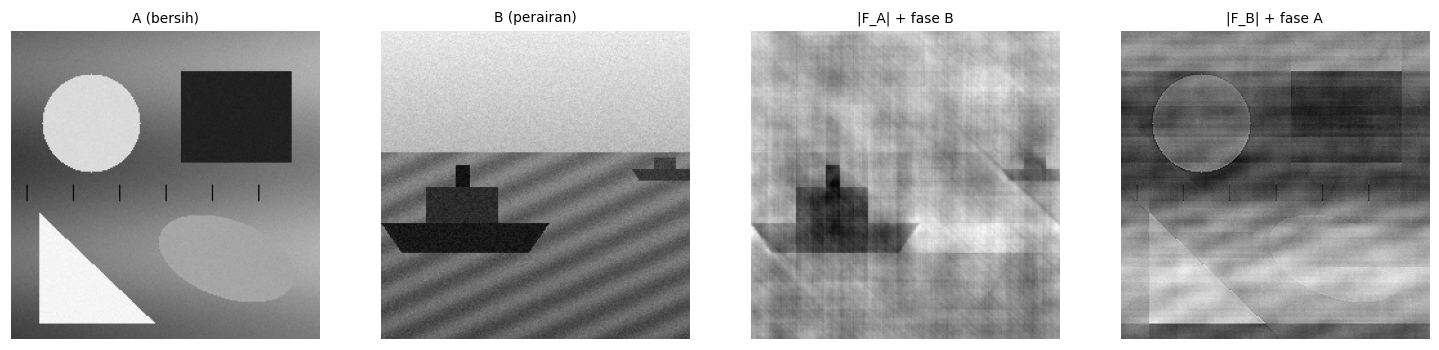

In [8]:
# TODO 2.3 — Tukar magnitudo dan fase antara A = bersih[8:248, 8:248] dan B = air[:, 60:300] (keduanya 240×240).
# Rekonstruksi |F_A|·e^{j·fase_B} dan |F_B|·e^{j·fase_A}, lalu hitung koefisien korelasi masing-masing dengan A dan B.
A = bersih[8:248, 8:248].astype(float)
B = air[:, 60:300].astype(float)
FA, FB = np.fft.fft2(A), np.fft.fft2(B)
h1 = np.fft.ifft2(np.abs(FA) * np.exp(1j * np.angle(FB))).real   # magnitudo A, fase B
h2 = np.fft.ifft2(np.abs(FB) * np.exp(1j * np.angle(FA))).real   # magnitudo B, fase A
r = lambda p, q: np.corrcoef(p.ravel(), q.ravel())[0, 1]
print(f'hasil 1 (|F_A|, fase B): r dengan A = {r(h1, A):+.4f}   r dengan B = {r(h1, B):+.4f}')
print(f'hasil 2 (|F_B|, fase A): r dengan A = {r(h2, A):+.4f}   r dengan B = {r(h2, B):+.4f}')
tampil([A, B, h1, h2], ['A (bersih)', 'B (perairan)', '|F_A| + fase B', '|F_B| + fase A'],
       skala=False, tinggi=3.2)

**Analisis 2.** (a) Kaitkan setiap puncak `kisi_` dengan pola pada citra. Mengapa garis tegak menghasilkan puncak pada sumbu v (mendatar di tampilan)? (b) Apa yang Anda simpulkan dari TODO 2.2 tentang informasi letak? (c) Dengan angka korelasi TODO 2.3, komponen mana yang membawa struktur?

*Jawaban Anda:*
(a). Pada citra kisi_ terdapat empat puncak frekuensi, yaitu pada posisi (0, ±16) dan (±24, ±12). Puncak (0, ±16) berasal dari pola garis tegak, sedangkan puncak (±24, ±12) berasal dari pola garis miring. Besarnya nilai setiap puncak juga sesuai dengan amplitudo yang digunakan saat membuat pola, yaitu 50 untuk garis tegak dan 40 untuk garis miring. Garis tegak menghasilkan puncak pada sumbu v karena perubahan intensitasnya hanya terjadi ke arah kolom, bukan ke arah baris. Karena itu, frekuensinya hanya muncul pada sumbu v. Setiap pola juga memiliki pasangan puncak karena citra yang digunakan memiliki nilai real.

(b). Dari hasil percobaan pada Tahap 2.2, pergeseran posisi citra ternyata tidak mengubah nilai magnitudonya. Hal ini terlihat dari selisih maksimum magnitudo yang sangat kecil, yaitu 5,8e−11 atau hampir nol. Namun, nilai fasenya mengalami perubahan yang cukup besar, dengan selisih maksimum 6,19 rad. Artinya, informasi mengenai letak atau posisi objek dalam citra tersimpan pada fase, sedangkan magnitudo tetap sama meskipun citra digeser.

(c). Berdasarkan hasil pengujian, citra yang menggunakan fase dari citra lain memiliki kemiripan lebih tinggi dengan citra yang fasenya digunakan. Nilai korelasinya mencapai 0,625, sedangkan kemiripan dengan citra yang magnitudonya digunakan justru rendah atau negatif. Jadi, dapat disimpulkan bahwa fase lebih berperan dalam mempertahankan bentuk dan struktur objek pada citra dibandingkan magnitudo.

## Bagian 3 &mdash; Penapisan lolos-rendah (35 menit)

Penapis dirancang terhadap jarak $D(u,v) = \sqrt{(u-P/2)^2 + (v-Q/2)^2}$ (Eq. 4-112):
ideal (Eq. 4-111), Butterworth $H = 1/(1+[D/D_0]^{2n})$ (Eq. 4-117), Gaussian $H = e^{-D^2/2D_0^2}$ (Eq. 4-116).

Delapan langkah Gonzalez §4.7: (1) P = 2M, Q = 2N; (2) lapisi citra; (3) kalikan $(-1)^{x+y}$; (4) DFT; (5) bangun H berukuran P&times;Q terpusat; (6) G = HF; (7) bagian nyata IDFT dikali $(-1)^{x+y}$; (8) ambil potongan M&times;N kiri atas.

In [9]:
# TODO 3.1 — Lengkapi pembangun penapis. Uji dengan D0 = 30 pada D = 30 dan D = 60:
# Butterworth n=2 -> 0,5000 dan 0,0588;  Gaussian -> 0,6065 dan 0,1353.
def jarak(P, Q):
    u = np.arange(P).reshape(-1, 1)
    v = np.arange(Q).reshape(1, -1)
    return np.sqrt((u - P / 2) ** 2 + (v - Q / 2) ** 2)
    ...  # TODO
def H_ideal(P, Q, D0):
    return (jarak(P, Q) <= D0).astype(float)
    ...  # TODO
def H_butterworth(P, Q, D0, n=2):
    return 1.0 / (1.0 + (jarak(P, Q) / D0) ** (2 * n))
    ...  # TODO
def H_gauss(P, Q, D0):
    return np.exp(-jarak(P, Q) ** 2 / (2.0 * D0 ** 2))
    ...  # TODO

Hb, Hg = H_butterworth(256, 256, 30, 2), H_gauss(256, 256, 30)
for D in (30, 60):
    print(f'D = {D}:  Butterworth n=2 = {Hb[128, 128 + D]:.4f}   Gaussian = {Hg[128, 128 + D]:.4f}')

D = 30:  Butterworth n=2 = 0.5000   Gaussian = 0.6065
D = 60:  Butterworth n=2 = 0.0588   Gaussian = 0.1353


In [10]:
# TODO 3.2 — Implementasikan delapan langkah sebagai saring(f, H, pad), dengan pad ∈ {'constant', 'reflect', 'edge'}.
# Uji: H = 1 di mana-mana harus mengembalikan f persis (selisih maks < 1e-9).
def saring(f, H, pad='reflect'):
    f = np.asarray(f, dtype=float)
    M, N = f.shape
    P, Q = H.shape

    if (P, Q) != (M, N):
        fp = np.pad(f, ((0, P - M), (0, Q - N)), mode=pad)
    else:
        fp = f.copy()
    x, y = np.indices((P, Q))
    s = (-1.0) ** (x + y)

    G = H * np.fft.fft2(fp * s)

    g = np.fft.ifft2(G).real * s
    return g[:M, :N]
    ...  # TODO

uji = saring(bersih, np.ones((512, 512)), 'reflect')
print('uji identitas (H = 1), selisih maks:', np.abs(uji - bersih).max())


uji identitas (H = 1), selisih maks: 8.526512829121202e-14


Rerata kolom 0–4    :
  asli                   91.986   selisih terhadap asli:   +0.000
  (a) tanpa pelapis     116.167   selisih terhadap asli:  +24.182
  (b) pelapis nol        56.383   selisih terhadap asli:  -35.603
  (c) pelapis cermin     92.920   selisih terhadap asli:   +0.934
Pembanding: rerata kolom 251–255 citra asli = 154.363


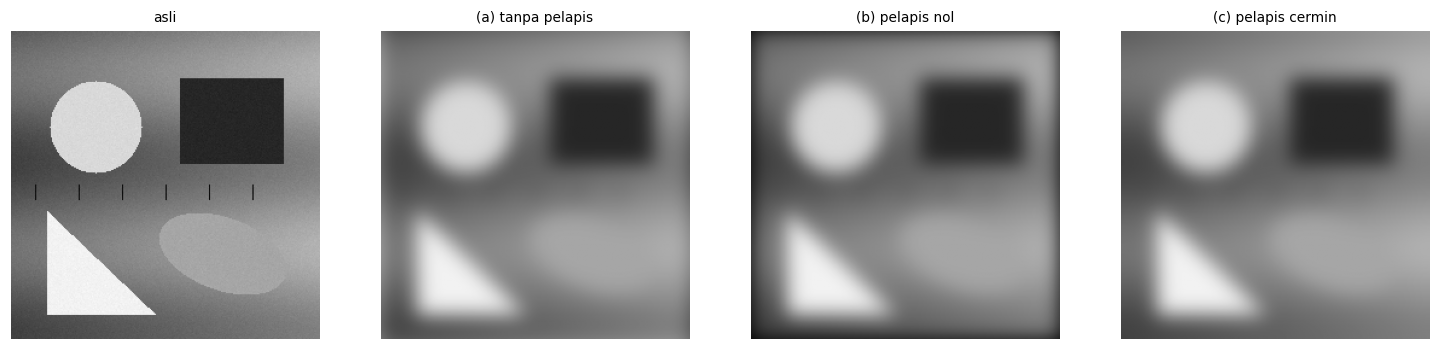

In [11]:
# TODO 3.3 — Pelapis dan wraparound. Terapkan Gaussian D0 = 10 pada `bersih` dengan tiga cara:
# (a) tanpa pelapis: H berukuran 256×256 dengan D0 = 5 (setara), pad tidak dipakai;
# (b) pelapis nol 512×512; (c) pelapis cermin 512×512.
# Laporkan rerata kolom 0–4 hasil masing-masing dan bandingkan dengan citra asli.
hasil_a = saring(bersih, H_gauss(256, 256, 5))
hasil_b = saring(bersih, H_gauss(512, 512, 10), 'constant')
hasil_c = saring(bersih, H_gauss(512, 512, 10), 'reflect')
asli = bersih.astype(float)
print('Rerata kolom 0–4    :')
for nama, im in [('asli', asli), ('(a) tanpa pelapis', hasil_a), ('(b) pelapis nol', hasil_b), ('(c) pelapis cermin', hasil_c)]:
    print(f'  {nama:20s} {im[:, 0:5].mean():8.3f}   selisih terhadap asli: {im[:, 0:5].mean() - asli[:, 0:5].mean():+8.3f}')
print('Pembanding: rerata kolom 251–255 citra asli =', round(asli[:, 251:256].mean(), 3))
tampil([asli, hasil_a, hasil_b, hasil_c], ['asli', '(a) tanpa pelapis', '(b) pelapis nol', '(c) pelapis cermin'],
       skala=True, tinggi=3.2)


penapis               minimum   maksimum
ideal                  -35.95     301.00
Butterworth n=1         -0.00     231.71
Butterworth n=2         -8.56     267.91
Butterworth n=5        -26.24     293.20
Butterworth n=20       -35.36     300.64
Gaussian                -0.00     251.28


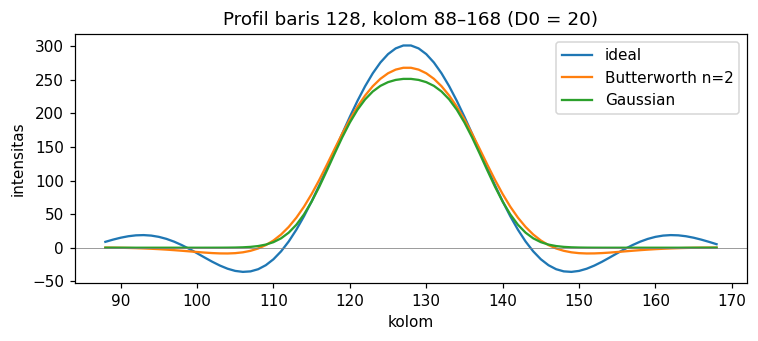

In [12]:
# TODO 3.4 — Riak (ringing). Pada `kotak_` (latar hitam, pakai pad='constant'), terapkan D0 = 20:
# ideal, Butterworth n = 1, 2, 5, 20, dan Gaussian. Laporkan nilai minimum dan maksimum hasil (sebelum clip),
# lalu gambar profil baris 128 kolom 88–168 untuk ideal, Butterworth n=2, dan Gaussian.
daftar_H = {
    'ideal':            H_ideal(512, 512, 20),
    'Butterworth n=1':  H_butterworth(512, 512, 20, 1),
    'Butterworth n=2':  H_butterworth(512, 512, 20, 2),
    'Butterworth n=5':  H_butterworth(512, 512, 20, 5),
    'Butterworth n=20': H_butterworth(512, 512, 20, 20),
    'Gaussian':         H_gauss(512, 512, 20),
}
hasil_riak = {}
print(f'{"penapis":18s} {"minimum":>10s} {"maksimum":>10s}')
for nama, H in daftar_H.items():
    g = saring(kotak_, H, 'constant')
    hasil_riak[nama] = g
    print(f'{nama:18s} {g.min():10.2f} {g.max():10.2f}')

plt.figure(figsize=(7, 3.2))
for nama in ['ideal', 'Butterworth n=2', 'Gaussian']:
    plt.plot(np.arange(88, 169), hasil_riak[nama][128, 88:169], label=nama)
plt.axhline(0, color='gray', lw=0.5); plt.legend(); plt.title('Profil baris 128, kolom 88–168 (D0 = 20)')
plt.xlabel('kolom'); plt.ylabel('intensitas'); plt.tight_layout(); plt.show()

In [13]:
# TODO 3.5 — Reduksi derau. Pada `berderau` (derau Gaussian σ = 20), bandingkan ketiga penapis untuk
# D0 ∈ {40, 60, 80, 100, 120, 160} (pelapis cermin). Susun tabel PSNR terhadap `bersih` dan tentukan D0 terbaik tiap penapis.
D0_list = [40, 60, 80, 100, 120, 160]
pembangun = {'ideal': H_ideal, 'Butterworth n=2': H_butterworth, 'Gaussian': H_gauss}
tabel_psnr = {n: [] for n in pembangun}
print(f'PSNR citra berderau tanpa penapis = {psnr(bersih, berderau):.2f} dB\n')
print(f'{"D0":>5s}' + ''.join(f'{n:>18s}' for n in pembangun))
for D0 in D0_list:
    baris = f'{D0:5d}'
    for n, fn in pembangun.items():
        g = np.clip(saring(berderau, fn(512, 512, D0), 'reflect'), 0, 255)
        p = psnr(bersih, g); tabel_psnr[n].append(p); baris += f'{p:18.2f}'
    print(baris)
print()
for n, p in tabel_psnr.items():
    i = int(np.argmax(p)); print(f'terbaik {n:16s}: D0 = {D0_list[i]:3d}  PSNR = {p[i]:.2f} dB')

PSNR citra berderau tanpa penapis = 22.26 dB

   D0             ideal   Butterworth n=2          Gaussian
   40             26.66             27.37             27.78
   60             27.78             28.58             28.84
   80             28.12             29.05             29.13
  100             28.01             29.05             28.93
  120             27.62             28.73             28.42
  160             26.40             27.61             27.06

terbaik ideal           : D0 =  80  PSNR = 28.12 dB
terbaik Butterworth n=2 : D0 =  80  PSNR = 29.05 dB
terbaik Gaussian        : D0 =  80  PSNR = 29.13 dB


In [14]:
# [Pengayaan] TODO 3.6 — Persentase daya yang diloloskan α (Eq. 4-113, 4-114) untuk lingkaran D0 = 5, 10, 20, 40, 80
# pada `bersih` yang dilapisi nol menjadi 512×512 dan dipusatkan.
fp = np.pad(bersih.astype(float), ((0, 256), (0, 256)))
Pw = np.abs(np.fft.fftshift(np.fft.fft2(fp))) ** 2
D = jarak(512, 512)
for D0 in (5, 10, 20, 40, 80):
    print(f'D0 = {D0:3d}:  α = {100 * Pw[D <= D0].sum() / Pw.sum():6.2f} %')

D0 =   5:  α =  89.77 %
D0 =  10:  α =  94.79 %
D0 =  20:  α =  97.26 %
D0 =  40:  α =  98.61 %
D0 =  80:  α =  99.31 %


**Analisis 3.** (a) Jelaskan dua artefak tepi pada TODO 3.3 dan mengapa pelapis cermin paling dekat dengan citra asli. (b) Dengan angka minimum TODO 3.4, urutkan penapis dari riak terkuat ke terlemah dan jelaskan penyebabnya. (c) Penapis mana yang memberi PSNR tertinggi pada TODO 3.5, pada D0 berapa? Mengapa ideal selalu terendah?

*Jawaban Anda:*
(a). Pada Tahap 3.3 terdapat dua jenis artefak tepi yang muncul akibat proses pelapisan citra.

Pertama, tanpa pelapis, bagian tepi citra menjadi lebih terang karena DFT menganggap citra memiliki pola berulang. Akibatnya, bagian tepi kiri dan kanan dianggap saling terhubung. Hal ini membuat nilai rata-rata kolom 0–4 meningkat dari 91,99 menjadi 116,17.

Kedua, pada pelapis nol, bagian tepi menjadi lebih gelap karena area tambahan di luar citra diisi dengan nilai nol. Nilai tersebut ikut memengaruhi perhitungan sehingga rata-rata kolom 0–4 turun menjadi 56,38.

Sementara itu, pelapis cermin menghasilkan nilai 92,92, yang paling mendekati nilai citra asli. Hal ini karena piksel di luar batas citra dibuat dengan meniru pantulan piksel di bagian tepi, sehingga perubahan intensitasnya lebih halus dan tidak menimbulkan perbedaan yang terlalu besar.

(b). Berdasarkan hasil percobaan, urutan penapis dari yang menghasilkan riak paling kuat hingga paling lemah adalah penapis ideal, Butterworth n=20, Butterworth n=5, Butterworth n=2, kemudian Butterworth n=1 dan Gaussian.

Penapis ideal menghasilkan riak paling besar karena pemotongan frekuensinya terjadi secara tiba-tiba. Hal ini menyebabkan munculnya osilasi atau perubahan nilai di sekitar tepi citra. Pada penapis Butterworth, semakin besar nilai n, bentuk penapisnya semakin mendekati penapis ideal sehingga riaknya juga semakin besar. Sementara itu, Gaussian dan Butterworth dengan n=1 memiliki perubahan yang lebih halus sehingga riak yang dihasilkan jauh lebih kecil.

(c). Berdasarkan hasil pengujian, penapis Gaussian menghasilkan PSNR tertinggi, yaitu 29,13 dB pada D0 = 80. Nilai ini sedikit lebih tinggi dibandingkan Butterworth n=2 yang menghasilkan 29,05 dB pada D0 yang sama. Sementara itu, penapis ideal hanya menghasilkan 28,12 dB.

Penapis ideal selalu memberikan hasil PSNR paling rendah karena menghasilkan riak di sekitar tepi citra. Riak tersebut menambah perbedaan antara citra hasil penapisan dengan citra bersih. Akibatnya, nilai kesalahan atau MSE menjadi lebih besar sehingga nilai PSNR menjadi lebih rendah.

## Bagian 4 &mdash; Lolos-tinggi dan kesetaraan spasial&ndash;frekuensi (25 menit)

$H_{HP} = 1 - H_{LP}$ (Eq. 4-118). Penekanan frekuensi tinggi: $g = \mathcal{F}^{-1}\{[k_1 + k_2 H_{HP}]F\}$ (Eq. 4-133); dengan $k_1 = 1$ ini setara unsharp masking (Eq. 4-132).

Pasangan Gaussian: kernel spasial bersimpangan baku $\sigma$ setara dengan GLPF pada persegi P&times;P dengan $D_0 = P/(2\pi\sigma)$.

GHPF D0=20 (8 langkah, pelapis cermin): rerata =   0.0057  min =  -117.54  maks =   119.07
GHPF tanpa pelapis (256x256, D0=10)   : rerata = 2.50e-16  min =  -117.54  maks =   119.07
H_HP pada pusat (DC) = 0.0


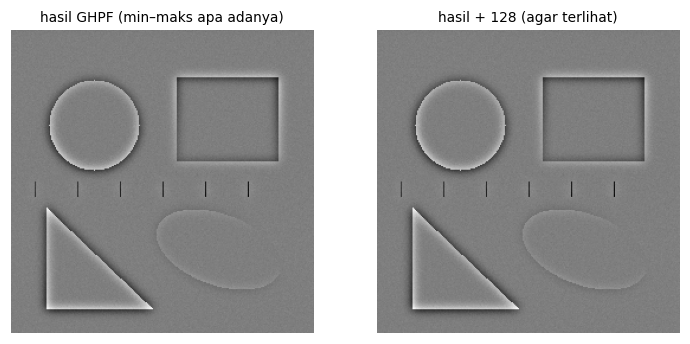

In [15]:
# TODO 4.1 — Terapkan GHPF D0 = 20 pada `bersih`. Laporkan rerata, minimum, dan maksimum hasil. Mengapa reratanya ≈ 0?
H_hp = 1 - H_gauss(512, 512, 20)
g_hp = saring(bersih, H_hp, 'reflect')
print(f'GHPF D0=20 (8 langkah, pelapis cermin): rerata = {g_hp.mean():8.4f}  min = {g_hp.min():8.2f}  maks = {g_hp.max():8.2f}')

g_hp0 = saring(bersih, 1 - H_gauss(256, 256, 10), 'reflect')
print(f'GHPF tanpa pelapis (256x256, D0=10)   : rerata = {g_hp0.mean():8.2e}  min = {g_hp0.min():8.2f}  maks = {g_hp0.max():8.2f}')
print(f'H_HP pada pusat (DC) = {H_hp[256, 256]}')
tampil([g_hp, np.clip(g_hp + 128, 0, 255)], ['hasil GHPF (min–maks apa adanya)', 'hasil + 128 (agar terlihat)'], skala=False, tinggi=3.2)

In [16]:
# TODO 4.2 — Penekanan frekuensi tinggi pada `kabur`: H = 1 + k·(1 − H_gauss(512, 512, D0)), D0 = 512/(2π·1,0).
# Untuk k ∈ {1; 2,5; 5; 8}, hitung PSNR terhadap `bersih` dengan pelapis nol dan pelapis cermin.
# Bandingkan dengan unsharp masking spasial Sub-CPMK-2 (f + k·(f − GaussianBlur 9×9 σ=1)).
D0_hfe = 512 / (2 * np.pi * 1.0)
Hlp = H_gauss(512, 512, D0_hfe)
print(f'D0 = {D0_hfe:.2f};  PSNR `kabur` tanpa penajaman = {psnr(bersih, kabur):.2f} dB (tengah 32:224 = {psnr(bersih[32:224, 32:224], kabur[32:224, 32:224]):.2f} dB)\n')
print(f'{"k":>4s} | {"nol":>7s} {"cermin":>7s} | {"nol(tengah)":>11s} {"cermin(tengah)":>14s} | {"unsharp":>7s}')
kabur_f = kabur.astype(float)
blur1 = cv2.GaussianBlur(kabur_f, (9, 9), 1.0)
for k in (1, 2.5, 5, 8):
    H = 1 + k * (1 - Hlp)
    gn = np.clip(saring(kabur, H, 'constant'), 0, 255)
    gc = np.clip(saring(kabur, H, 'reflect'), 0, 255)
    gu = np.clip(kabur_f + k * (kabur_f - blur1), 0, 255)
    c = (slice(32, 224), slice(32, 224))
    print(f'{k:4.1f} | {psnr(bersih, gn):7.2f} {psnr(bersih, gc):7.2f} | '
          f'{psnr(bersih[c], gn[c]):11.2f} {psnr(bersih[c], gc[c]):14.2f} | {psnr(bersih, gu):7.2f}')


D0 = 81.49;  PSNR `kabur` tanpa penajaman = 29.50 dB (tengah 32:224 = 29.05 dB)

   k |     nol  cermin | nol(tengah) cermin(tengah) | unsharp
 1.0 |   28.91   30.21 |       29.73          29.73 |   30.21
 2.5 |   25.98   31.01 |       30.47          30.47 |   31.01
 5.0 |   23.20   31.20 |       30.56          30.56 |   31.20
 8.0 |   21.91   29.86 |       29.06          29.06 |   29.86


In [17]:
# TODO 4.3 — Kesetaraan. Bandingkan GLPF D0 = 512/(2π·2) (pad='constant') dengan cv2.GaussianBlur(berderau, (17, 17), 2,
# borderType=cv2.BORDER_CONSTANT) dalam float. Laporkan selisih mutlak maksimum dan rerata.
g_frek = saring(berderau, H_gauss(512, 512, 512 / (2 * np.pi * 2)), 'constant')
g_spasial = cv2.GaussianBlur(berderau.astype(np.float64), (17, 17), 2, borderType=cv2.BORDER_CONSTANT)
sel = np.abs(g_frek - g_spasial)
print(f'selisih mutlak maks  = {sel.max():.4e}')
print(f'selisih mutlak rerata = {sel.mean():.4e}')

selisih mutlak maks  = 3.3646e-03
selisih mutlak rerata = 4.0997e-04


In [18]:
# [Pengayaan] TODO 4.4 — Biaya. Hitung keunggulan teoretis C_n(m) = m² / (4 log2 M) (Eq. 4-1) untuk M = 512 dan m = 3, 5, 7, 9, 15, 31,
# lalu ukur waktu scipy.signal.convolve2d (langsung) dan scipy.signal.fftconvolve (FFT) pada citra 512×512 dengan kernel rerata m×m.
# Catatan: jangan memakai cv2.filter2D sebagai pembanding "langsung" — fungsi itu otomatis beralih ke DFT untuk kernel besar.
from scipy.signal import convolve2d, fftconvolve
rng_t = np.random.default_rng(3)
img512 = rng_t.random((512, 512))
print(f'{"m":>3s} {"C_n(m)":>8s} {"langsung (ms)":>14s} {"FFT (ms)":>10s} {"nisbah":>8s}')
for m in (3, 5, 7, 9, 15, 31):
    ker = np.ones((m, m)) / m ** 2
    t0 = time.perf_counter(); convolve2d(img512, ker, mode='same'); t_d = time.perf_counter() - t0
    t0 = time.perf_counter(); fftconvolve(img512, ker, mode='same'); t_f = time.perf_counter() - t0
    print(f'{m:3d} {m**2 / (4 * np.log2(512)):8.2f} {t_d*1000:14.1f} {t_f*1000:10.1f} {t_d / t_f:8.2f}')


  m   C_n(m)  langsung (ms)   FFT (ms)   nisbah
  3     0.25           20.6       14.7     1.41
  5     0.69           29.3       10.7     2.74
  7     1.36           49.3       11.3     4.36
  9     2.25           73.0       10.8     6.78
 15     6.25          173.6       12.0    14.46
 31    26.69          637.0       15.8    40.29


**Analisis 4.** (a) Mengapa rerata GHPF ≈ 0? Apa akibatnya bagi tampilan? (b) Dengan angka TODO 4.2, jelaskan mengapa pelapis nol merusak penekanan frekuensi tinggi sementara pada penghalusan pengaruhnya kecil di bagian tengah. (c) Apa yang dibuktikan TODO 4.3 tentang hubungan Bab 3 dan Bab 4?

*Jawaban Anda:*
(a). Rata-rata hasil GHPF mendekati nol karena penapis ini menghilangkan komponen DC atau komponen yang menunjukkan nilai kecerahan rata-rata citra. Hal ini terjadi karena nilai H_HP pada frekuensi pusat adalah nol.

Akibatnya, hasil penapisan memiliki nilai piksel positif dan negatif. Pada percobaan, nilai minimumnya adalah −117,54 dan maksimumnya 119,07. Jika langsung ditampilkan seperti citra biasa dengan rentang 0–255, sebagian besar tampilannya akan terlihat hitam karena nilai negatif dipotong menjadi nol. Oleh karena itu, hasil GHPF perlu digeser atau disesuaikan skalanya agar pola tepi objek bisa terlihat dengan jelas.

(b). Pelapis nol memberikan pengaruh yang cukup besar ketika digunakan untuk penekanan frekuensi tinggi. Hal ini terlihat dari hasil PSNR pada k = 5, yaitu hanya 23,20 dB, sedangkan pelapis cermin mencapai 31,20 dB.

Penyebabnya adalah pelapis nol menciptakan perbedaan intensitas yang tajam antara tepi citra dan area tambahan yang bernilai nol. Ketika frekuensi tinggi diperkuat, perbedaan tersebut ikut diperkuat sehingga menghasilkan gangguan pada tepi citra.

Berbeda dengan proses penghalusan, pengaruh pelapis nol tidak terlalu besar di bagian tengah karena proses tersebut hanya meratakan perubahan intensitas. Hal ini dibuktikan dari nilai PSNR pada bagian tengah citra yang sama, yaitu 30,56 dB untuk pelapis nol maupun cermin.

Dari hasil percobaan juga terlihat bahwa pelapis cermin memberikan hasil terbaik pada k = 5 dengan PSNR 31,20 dB. Hasilnya bahkan sama dengan metode unsharp masking pada domain spasial. Namun, ketika k dinaikkan menjadi 8, kualitasnya mulai menurun karena penajaman yang dilakukan terlalu kuat.

(c). Hasil percobaan menunjukkan bahwa GLPF pada domain frekuensi memberikan hasil yang hampir sama dengan Gaussian Blur pada domain spasial. Perbedaan maksimum keduanya hanya 3,4e−3 dengan rata-rata selisih 4,1e−4.

## Bagian 5 &mdash; Studi kasus: derau periodik pada citra perairan (15 menit)

`air_garis` adalah citra perairan yang terkena interferensi periodik, seperti gangguan elektronik pada kamera pengawas. Tujuan: menghapus interferensi tanpa mengaburkan kapal. Ukur dengan PSNR terhadap `air` dan CNR kapal&ndash;laut.

**Catatan:** penapisan selektif dikerjakan tanpa pelapis karena interferensi di sini tepat berkala terhadap ukuran citra. Citra sintetis tidak boleh dipakai untuk menyimpulkan kinerja pada data sungguhan.

Enam puncak terbesar (di luar lingkaran r = 6):
  (Δbaris, Δkolom) = (  24,   36)   |F| =   954320.0
  (Δbaris, Δkolom) = ( -24,  -36)   |F| =   954320.0
  (Δbaris, Δkolom) = (  -7,    0)   |F| =   122662.0
  (Δbaris, Δkolom) = (   7,    0)   |F| =   122662.0
  (Δbaris, Δkolom) = (  10,    6)   |F| =   109208.5
  (Δbaris, Δkolom) = ( -10,   -6)   |F| =   109208.5


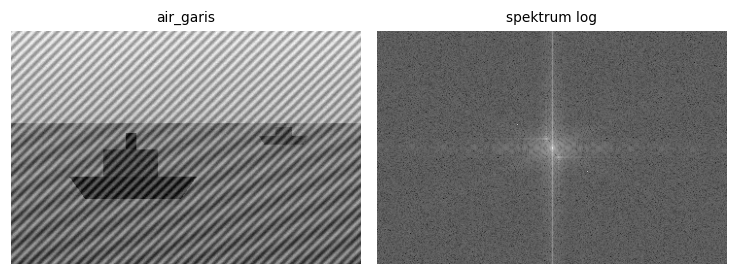

In [19]:
# TODO 5.1 — Cari puncak derau. Hitung spektrum terpusat, nolkan lingkaran berjari-jari 6 di sekitar pusat,
# lalu laporkan enam puncak terbesar sebagai (Δbaris, Δkolom) terhadap pusat. Pasangan mana yang derau?
kapal, laut = masker_perairan()
def cnr(im):
    im = im.astype(float); return abs(im[kapal].mean() - im[laut].mean()) / im[laut].std()
k8 = kapal.astype(np.uint8); tepi = (cv2.dilate(k8, np.ones((3, 3))) - cv2.erode(k8, np.ones((3, 3)))) > 0
def rasio_tepi(im):
    """Rerata magnitudo Sobel pada piksel batas kapal, relatif terhadap citra bersih (1 = setajam aslinya)."""
    g = lambda z: np.hypot(cv2.Sobel(z.astype(float), cv2.CV_64F, 1, 0), cv2.Sobel(z.astype(float), cv2.CV_64F, 0, 1))[tepi].mean()
    return g(im) / g(air)

Fg = np.fft.fftshift(np.fft.fft2(air_garis.astype(float)))
Mg = np.abs(Fg)
H_, W_ = Mg.shape
pb, pk = H_ // 2, W_ // 2                       # pusat spektrum
yy_, xx_ = np.indices(Mg.shape)
Mg_c = Mg.copy()
Mg_c[(yy_ - pb) ** 2 + (xx_ - pk) ** 2 <= 6 ** 2] = 0
idx = np.argsort(Mg_c.ravel())[::-1][:6]
print('Enam puncak terbesar (di luar lingkaran r = 6):')
for i in idx:
    r_, c_ = divmod(i, W_)
    print(f'  (Δbaris, Δkolom) = ({r_ - pb:4d}, {c_ - pk:4d})   |F| = {Mg_c.ravel()[i]:10.1f}')
tampil([air_garis, np.log1p(Mg)], ['air_garis', 'spektrum log'], skala=False, tinggi=3.2)
PUNCAK_DERAU = (24, 36)

Acuan `air` (bersih): CNR = 3.81   rasio tepi = 1.000

(a) tanpa penapis          PSNR =   24.26 dB   CNR =   1.42   rasio tepi = 1.296
(b) GLPF D0 = 40           PSNR =   37.18 dB   CNR =   4.02   rasio tepi = 0.358
(b) GLPF D0 = 60           PSNR =   32.18 dB   CNR =   2.86   rasio tepi = 0.564
(b) GLPF D0 = 80           PSNR =   28.92 dB   CNR =   2.20   rasio tepi = 0.756
(c) takik D0 = 2           PSNR =   75.93 dB   CNR =   3.81   rasio tepi = 1.000
(c) takik D0 = 3           PSNR =   71.32 dB   CNR =   3.81   rasio tepi = 0.999
(c) takik D0 = 5           PSNR =   65.80 dB   CNR =   3.81   rasio tepi = 0.995
(c) takik D0 = 8           PSNR =   61.10 dB   CNR =   3.81   rasio tepi = 0.987

Takik SATU puncak saja:
  D0 = 3: |bagian imajiner| maks = 11.1794   (bila dua puncak: 2.34e-14)

takik D0=3 + puncak (±7,0) PSNR =   21.86 dB   CNR =   3.05   rasio tepi = 0.934


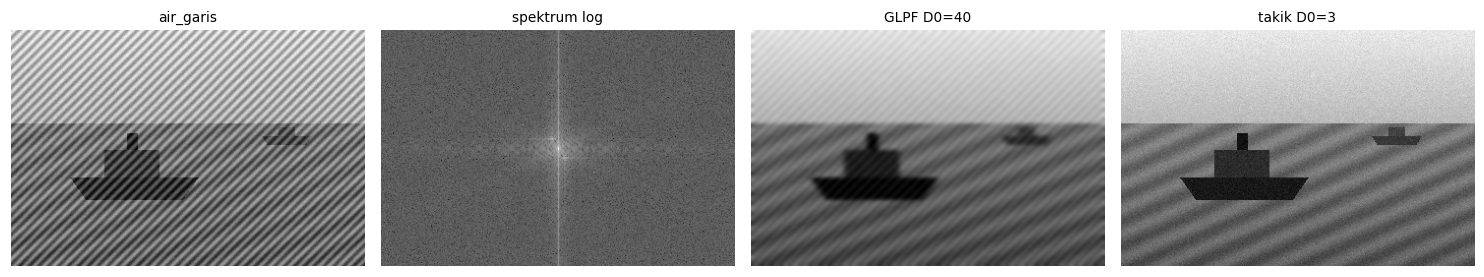

In [20]:
# TODO 5.2 — Bandingkan: (a) tanpa penapis; (b) GLPF (8 langkah, pelapis cermin) D0 ∈ {40, 60, 80};
# (c) penapis takik Gaussian (Eq. 4-151) pada pasangan puncak derau dengan D0 ∈ {2, 3, 5, 8}, tanpa pelapis.
# Untuk setiap hasil laporkan PSNR terhadap `air`, CNR, dan rasio_tepi. Lalu coba takik pada SATU puncak saja dan laporkan
# nilai mutlak maksimum bagian imajiner hasil IDFT.
U0, V0 = PUNCAK_DERAU      # (Δbaris, Δkolom) dari TODO 5.1

def H_takik(P, Q, D0, pasang=True):
    """Takik Gaussian: H = Π [1 − exp(−D_k²/2D0²)]; pasang=True menakik (u0,v0) dan (−u0,−v0)."""
    u = np.arange(P).reshape(-1, 1); v = np.arange(Q).reshape(1, -1)
    D2 = lambda du, dv: (u - P / 2 - du) ** 2 + (v - Q / 2 - dv) ** 2
    H = 1 - np.exp(-D2(U0, V0) / (2 * D0 ** 2))
    if pasang:
        H = H * (1 - np.exp(-D2(-U0, -V0) / (2 * D0 ** 2)))
    return H

def saring_takik(f, D0, pasang=True):
    F = np.fft.fftshift(np.fft.fft2(f.astype(float)))
    return np.fft.ifft2(np.fft.ifftshift(F * H_takik(*f.shape, D0, pasang)))     # kompleks

def ukur(nama, im):
    im = np.clip(im, 0, 255)
    print(f'{nama:26s} PSNR = {psnr(air, im):7.2f} dB   CNR = {cnr(im):6.2f}   rasio tepi = {rasio_tepi(im):5.3f}')

print(f'Acuan `air` (bersih): CNR = {cnr(air):.2f}   rasio tepi = {rasio_tepi(air):.3f}\n')
ukur('(a) tanpa penapis', air_garis)
hasil_glpf = {}
for D0 in (40, 60, 80):
    hasil_glpf[D0] = saring(air_garis, H_gauss(480, 720, D0), 'reflect'); ukur(f'(b) GLPF D0 = {D0}', hasil_glpf[D0])
hasil_takik = {}
for D0 in (2, 3, 5, 8):
    hasil_takik[D0] = saring_takik(air_garis, D0).real; ukur(f'(c) takik D0 = {D0}', hasil_takik[D0])

print('\nTakik SATU puncak saja:')
for D0 in (3,):
    g1 = saring_takik(air_garis, D0, pasang=False)
    print(f'  D0 = {D0}: |bagian imajiner| maks = {np.abs(g1.imag).max():.4f}   (bila dua puncak: {np.abs(saring_takik(air_garis, D0).imag).max():.2e})')

# Tambahan untuk Analisis 5(c): bila pasangan puncak adegan (±7, 0) ikut ditakik (D0 = 3)
u_ = np.arange(240).reshape(-1, 1); v_ = np.arange(360).reshape(1, -1)
D2e = lambda du, dv: (u_ - 120 - du) ** 2 + (v_ - 180 - dv) ** 2
H_ekstra = H_takik(240, 360, 3) * (1 - np.exp(-D2e(7, 0) / 18)) * (1 - np.exp(-D2e(-7, 0) / 18))
F_ = np.fft.fftshift(np.fft.fft2(air_garis.astype(float)))
g_ekstra = np.fft.ifft2(np.fft.ifftshift(F_ * H_ekstra)).real
print()
ukur('takik D0=3 + puncak (±7,0)', g_ekstra)

tampil([air_garis, np.log1p(Mg), np.clip(hasil_glpf[40], 0, 255), np.clip(hasil_takik[3], 0, 255)],
       ['air_garis', 'spektrum log', 'GLPF D0=40', 'takik D0=3'], skala=False, tinggi=3.0)


**Analisis 5.** (a) GLPF dengan D0 kecil dapat memberi CNR **lebih tinggi** daripada citra bersih. Apakah itu berarti GLPF lebih baik daripada takik? Jawab dengan PSNR dan rasio_tepi. (b) Mengapa kedua puncak harus dihapus bersamaan? Jelaskan dengan angka bagian imajiner. (c) Puncak lain di dekat pusat (misalnya Δbaris ±7) berasal dari apa, dan apa akibatnya bila ikut ditakik? (d) Sebutkan satu alasan mengapa hasil sehampir sempurna ini tidak akan terulang pada citra kamera sungguhan.

*Jawaban Anda:*
(a). GLPF dengan nilai D0 kecil memang dapat menghasilkan nilai CNR yang lebih tinggi dibandingkan citra bersih. Namun, hal tersebut tidak berarti GLPF lebih baik daripada penapis takik.

Sebagai contoh, GLPF dengan D0 = 40 menghasilkan CNR sebesar 4,02, lebih tinggi dibandingkan citra bersih yang hanya 3,81. Akan tetapi, nilai PSNR-nya hanya 37,18 dB dan rasio tepinya sebesar 0,358. Artinya, ketajaman tepi kapal hanya tersisa sekitar 36% dari kondisi aslinya karena objek ikut menjadi kabur.

Sementara itu, penapis takik dengan D0 = 3 menghasilkan PSNR sebesar 71,32 dB, CNR 3,81, dan rasio tepi 0,999. Hasil ini menunjukkan bahwa penapis takik mampu menghilangkan derau tanpa banyak mengubah bentuk dan ketajaman objek. Jadi, nilai CNR saja tidak cukup untuk menentukan kualitas hasil penapisan karena perlu melihat PSNR dan rasio tepi juga.

(b). Kedua puncak harus dihapus secara bersamaan karena derau berbentuk sinusoida pada citra nyata akan menghasilkan dua puncak yang saling berpasangan atau disebut pasangan konjugat. Jika hanya satu puncak yang dihapus, keseimbangan spektrum akan terganggu sehingga hasil IDFT memiliki bagian imajiner.

Hal ini terbukti dari hasil percobaan. Ketika hanya satu puncak yang dihapus, nilai maksimum bagian imajinernya mencapai 11,18. Sedangkan ketika kedua puncak dihapus bersamaan, nilainya hanya 2,3e−14 atau hampir nol. Jadi, menghapus kedua puncak sekaligus diperlukan agar hasil citra kembali menjadi bilangan real.

(c). Puncak lain yang berada dekat dengan pusat, seperti (±7, 0) dan (±10, 6), berasal dari pola atau objek yang memang ada di dalam citra, bukan dari derau. Puncak (±7, 0) kemungkinan berasal dari batas antara langit dan laut, sedangkan puncak (±10, 6) berasal dari pola gelombang laut.

Jika puncak tersebut ikut dihapus, informasi asli pada citra juga akan ikut hilang. Hal ini terlihat ketika puncak (±7, 0) ikut ditakik, nilai PSNR turun drastis dari 71,32 dB menjadi 21,86 dB. Nilai CNR juga turun dari 3,81 menjadi 3,05. Oleh karena itu, penghapusan frekuensi harus dilakukan dengan hati-hati agar tidak menghilangkan bagian penting dari citra.

(d). Hasil yang hampir sempurna pada percobaan ini sulit diperoleh pada citra dari kamera sungguhan karena derau pada citra asli biasanya tidak memiliki frekuensi yang benar-benar teratur. Pada percobaan, gangguan dibuat secara periodik sehingga energinya terkumpul pada titik frekuensi tertentu dan mudah dihilangkan menggunakan penapis takik.

Sedangkan pada citra kamera sungguhan, frekuensi gangguan bisa menyebar ke beberapa titik di sekitar puncak. Selain itu, terdapat juga derau lain yang berasal dari sensor kamera. Akibatnya, proses penghilangan derau tidak akan sesempurna hasil percobaan ini.

---
## Bagian 6 &mdash; Daftar periksa (10 menit)

- [x] `dft1` dan `dft2` cocok dengan np.fft (selisih < 1e−9) dan contoh kuliah terpenuhi
- [x] F(0,0) = MN · rerata; pemusatan (−1)^(x+y) = fftshift
- [x] Uji identitas `saring` lolos (selisih < 1e−9)
- [x] Tabel riak, tabel PSNR penapis, dan tabel penekanan frekuensi tinggi lengkap
- [x] Setiap blok Analisis memuat angka dari keluaran Anda
- [x] Penggunaan alat bantu AI (bila ada) dicantumkan
- [x] Berkas dinamai `PraktikumPCD_SubCPMK3_NIM_Nama.ipynb` dan dijalankan penuh

Untuk penggunaan AI: ChatGPT
bagian
1. Membantu memahami konsep Transformasi Fourier (DFT), penapisan pada domain frekuensi, serta proses pengolahan citra.
2. Membantu menjelaskan fungsi dan cara kerja beberapa kode Python yang digunakan dalam praktikum.
3. Membantu memahami hasil pengujian dan menganalisis perbedaan hasil dari setiap percobaan.
4. Membantu merapikan penjelasan pada bagian analisis agar lebih mudah dipahami.